# 22 — Détection spatiale sur les waypoints (Panel Lémanique 2023)

Méthode géométrique calculée **uniquement à partir des waypoints**, sur le **corpus commun** de legs (`legs/corpus_by_leg.parquet`, filtres `leg_filters` du YAML, construit à l'étape 01) : exactement les mêmes legs que la méthode temporelle. Destination = **dernier waypoint voiture**.

**Fenêtre de destination** : cercle de rayon `leg_filters.destination_window_radius_m` autour de la destination ; la fenêtre part du point d'entrée (intersection interpolée de la trace avec le cercle lors de sa dernière entrée) et va jusqu'au dernier waypoint.

**Métriques** : 1. distance excessive (si le routage est disponible) ; 2. distance et temps dans le cercle, mesurés entre waypoints ; 3. boucle (repassage) ; 4. recul : distance parcourue en s'éloignant de la destination (déplacements projetés négatifs sur l'axe entrée → destination) ; 5. passage près de l'activité (ou de la destination) hors des derniers mètres.

**Sorties** : `data/spatial_waypoints_candidates.parquet` (détail), `legs/spatial_by_leg.parquet` (collection, une ligne par leg), `data/routing_requests.parquet` (demandes de routage), `reports/22_spatial_*`.

Logique : `src/parking_search_prediction/spatial_waypoints.py`.

In [1]:
CONFIG_NAME = "full_waypoints.yaml"
OUTPUT_DIR = "outputs/pl23"
STAYPOINTS_FILE = "Data/GPS/pl23/20241120_dump_situee/241120_staypoints.geojson"   # None : référence = destination

# Corpus commun : les legs traitées sont celles de legs/corpus_by_leg.parquet (filtres `leg_filters` du
# YAML, construit à l'étape 01) — exactement les mêmes que pour la méthode temporelle (notebook 32).
# Le rayon du cercle de destination est leg_filters.destination_window_radius_m.

# Règles propres à la méthode spatiale, EN PLUS du corpus (None / False = désactivée).
# Toutes désactivées : la méthode spatiale traite exactement le corpus commun.
EXCLUSIONS = {
    "require_last_car_leg_in_trip": False,        # seulement la dernière leg voiture du trip
    "allowed_post_car_modes": ["Mode::Walk"],     # modes autorisés après la voiture…
    "exclude_non_allowed_post_car_modes": False,  # … exclure si un autre mode suit (ex. bus)
    "min_speed_kmh": None,
    "max_speed_kmh": None,
    "max_parking_activity_distance_m": None,      # stationnement à moins de x m de l'activité (si localisée)
    "require_activity_location": False,
    "min_window_points": None,                    # waypoints minimum dans le cercle
    "exclude_starts_in_buffer": False,            # exclure les legs qui démarrent déjà dans le cercle
}

# Métriques
METRICS = {
    "min_step_m": 10,                     # anti-bruit GPS : waypoint ignoré s'il est à < 10 m du précédent retenu
    "loop_radius_m": 30,                  # boucle : repassage à moins de X m…
    "loop_min_delay_s": 60,               # … d'un point visité au moins Y s plus tôt…
    "loop_min_excursion_m": 100,          # … après s'en être éloigné d'au moins Z m
    "near_reference_radius_m": 25,        # passage à moins de x m de la référence…
    "near_reference_exclusion_end_m": 150,   # … hors des 150 derniers mètres
    "reference_point": "activity",        # "activity" (repli sur la destination) ou "destination"
}

# Détection : critères combinés par « ou » (None / False désactive)
DETECTION = {
    "detect_loop": True,
    "detect_passes_near_reference": True,
    "detect_backtrack_min_m": 200,        # distance parcourue en s'éloignant de la destination
    "detect_window_distance_min_m": None, # distance brute dans le cercle (contient l'approche normale)
    "detect_dist_excess_min_m": 200,      # seulement si legs/routing_by_leg.parquet existe
    "detect_dist_excess_matched_min_m": 200,  # détour sur la trace appariée (map matching) ; None = désactivé
    "search_measure": "excess_if_available",   # ou "window"
}
# Plus court chemin de référence pour les distances excessives :
#   "raw_od"     : point d'entrée interpolé → dernier waypoint brut
#   "matched_od" : 1re → dernière position recalée par le map matching (mêmes extrémités que la trace appariée)
ROUTING_REFERENCE = "matched_od"  # "raw_od" ou "matched_od"

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from parking_search_prediction.config import load_config
from parking_search_prediction.spatial_waypoints import (
    plot_metrics_panel, run_spatial_detection, spatial_settings, write_routing_requests,
)
from parking_search_prediction.indicators import filter_legs

config = load_config(PROJECT_ROOT / "config" / CONFIG_NAME)
config["paths"]["output_dir"] = OUTPUT_DIR
cfg = config.setdefault("spatial_waypoints", {})
cfg.update({"staypoints_file": STAYPOINTS_FILE, "routing_reference": ROUTING_REFERENCE, **EXCLUSIONS, **METRICS, **DETECTION})
display(pd.Series(config["leg_filters"], name="corpus commun (leg_filters du YAML)"))

result = run_spatial_detection(config, write_requests=False)
legs = result["legs"]
pd.Series({k: v for k, v in result["summary"].items() if not isinstance(v, dict)}, name="détection spatiale")

max_accuracy_m                                                                     100
min_leg_points                                                                      20
min_leg_duration_s                                                                 300
min_leg_length_m                                                                   500
min_origin_destination_distance_m                                                  100
max_window_gap_s                                                                   120
max_trip_duration_s                                                              18000
destination_window_radius_m                                                       1000
exclude_tunnel_h3_destinations                                                    True
tunnel_h3_resolution                                                                 8
tunnel_h3_cells                      [881f91ad29fffff, 881f91ad07fffff, 881f91af19f...
Name: corpus commun (leg_filters du YAML), 

[spatial] partie 1/16 — 2550 legs — 2 s
[spatial] partie 2/16 — 4294 legs — 4 s
[spatial] partie 3/16 — 6546 legs — 6 s
[spatial] partie 4/16 — 8929 legs — 8 s
[spatial] partie 5/16 — 11405 legs — 10 s
[spatial] partie 6/16 — 13913 legs — 12 s
[spatial] partie 7/16 — 16261 legs — 14 s
[spatial] partie 8/16 — 18401 legs — 16 s
[spatial] partie 9/16 — 21097 legs — 18 s
[spatial] partie 10/16 — 23059 legs — 20 s
[spatial] partie 11/16 — 25533 legs — 22 s
[spatial] partie 12/16 — 27607 legs — 24 s
[spatial] partie 13/16 — 29446 legs — 26 s
[spatial] partie 14/16 — 31624 legs — 28 s
[spatial] partie 15/16 — 34024 legs — 30 s
[spatial] partie 16/16 — 35896 legs — 31 s


legs_corpus                                                               35896
legs_eligible                                                             35896
legs_detected                                                              8925
detected_share_of_eligible                                             0.248635
routing_available                                                          True
activity_located_share                                                 0.996378
starts_in_buffer                                                            419
routing_requests                                                           None
detail_table                  /Users/maximiliantrique/Documents/Projet_pytho...
collection_table              /Users/maximiliantrique/Documents/Projet_pytho...
seconds                                                                    67.2
Name: détection spatiale, dtype: object

## Dictionnaire des variables

In [3]:
dictionary = result["dictionary"]
with pd.option_context("display.max_colwidth", None, "display.max_rows", 200):
    for section, block in dictionary.groupby("section", sort=False):
        display(block[["variable", "description"]].set_index("variable").rename_axis(section))

,description
Contexte de la leg et du trip,
leg_id,Identifiant de leg.
source_user_id,Participant (UUID Motiontag).
trip_id,Trip de la leg.
trip_purpose,Motif déclaré du trip.
purpose_agg,Motif regroupé (table de l'étape 23).
time_of_day_end_trip,Tranche horaire de fin de leg (heure locale).
weekday,Jour de fin de leg (heure locale).
trip_duration_seconds,"Durée du trip, s."
is_last_car_leg_in_trip,Dernière leg voiture du trip.


,description
Géométrie de base (waypoints),
spatial_n_waypoints,Nombre de waypoints voiture de la leg.
spatial_leg_duration_s,"Durée entre premier et dernier waypoint, s."
spatial_leg_length_m,"Longueur de la trace (somme des pas entre waypoints filtrés du bruit GPS), m."
spatial_leg_speed_kmh,"Vitesse moyenne (longueur / durée), km/h."
spatial_origin_lon,Premier waypoint (longitude).
spatial_origin_lat,Premier waypoint (latitude).
spatial_destination_lon,Destination = dernier waypoint (longitude).
spatial_destination_lat,Destination = dernier waypoint (latitude).
spatial_origin_destination_distance_m,"Distance à vol d'oiseau origine → destination, m."


,description
Éligibilité et exclusions,
spatial_eligible,Leg du corpus commun éligible pour la méthode spatiale (aucune règle spatiale propre active ne s'applique ; toutes désactivées par défaut).
spatial_exclusion_reason,Première règle d'exclusion rencontrée (ordre de la liste des règles).
spatial_exclusion_reasons,"Toutes les règles d'exclusion vérifiées, séparées par « ; »."


,description
Fenêtre de destination,
spatial_entry_lon,"Point d'entrée dans le cercle (longitude, interpolé)."
spatial_entry_lat,"Point d'entrée dans le cercle (latitude, interpolé)."
spatial_entry_at,"Instant d'entrée dans le cercle (interpolé, UTC)."
spatial_window_points,Waypoints dans la fenêtre (après filtre anti-bruit min_step_m).
spatial_window_max_gap_s,"Plus long intervalle entre waypoints dans la fenêtre, s."


,description
Métrique 1 — distance excessive,
spatial_dist_excess_m,"Distance entre waypoints dans la fenêtre − plus court chemin de la référence (spatial_routing_reference), m (NaN sans routage)."
spatial_routing_reference,Plus court chemin de référence : raw_od (point d'entrée interpolé → dernier waypoint) ou matched_od (1re → dernière position recalée par le map matching).
spatial_routed_distance_m,"Plus court chemin de la référence choisie, m."


,description
Métrique 1b — distance excessive sur trace appariée,
spatial_matched_distance_m,"Longueur de la fenêtre appariée sur le réseau (OSRM /match), m (NaN si non appariée)."
spatial_matching_confidence,Confiance moyenne de l'appariement OSRM (0–1).
spatial_matching_n_matchings,"Nombre de tronçons appariés (> 1 : trace coupée par un trou, longueur sous-estimée)."
spatial_matching_detour_steps,"Pas appariés dont la distance sur le réseau dépasse 3 × le vol d'oiseau entre deux points recalés (détour forcé : sens unique, rue absente du graphe, mauvaise chaussée)."
spatial_dist_excess_matched_m,"Longueur appariée − plus court chemin de la référence, m : distance excessive avec la trace appariée comme distance effective (avec matched_od, mêmes extrémités sur le réseau)."


,description
Métrique 2 — distance et temps dans le cercle,
spatial_window_distance_m,"Distance parcourue dans le cercle, mesurée entre waypoints, m."
spatial_window_duration_s,"Temps passé dans le cercle, mesuré entre waypoints, s."


,description
Métrique 3 — boucle,
spatial_loop_detected,"Repassage : un waypoint revient à moins de X m d'un point visité ≥ Y s plus tôt, après une excursion."
spatial_loop_revisit_points,Nombre de waypoints en repassage.
spatial_loop_first_revisit_to_end_s,"Temps entre le premier repassage et la fin de la leg, s."


,description
Métrique 4 — recul (éloignement de la destination),
spatial_backtrack_distance_m,"Σ des déplacements entre waypoints consécutifs dont la projection sur l'axe entrée → destination est négative (on s'éloigne de la destination), m ; 0 = approche sans recul."
spatial_approach_efficiency_total_sum,"Σ de toutes les projections sur l'axe entrée → destination (+ en avançant, 0 de côté, − en reculant), m. Avances et reculs se compensent : vaut la distance entrée → destination (≈ le rayon) quel que soit le chemin ; contrôle de cohérence, non discriminant."
spatial_backtrack_share,Part de la distance parcourue dans le cercle en s'éloignant de la destination.


,description
Métrique 5 — passage près du point de référence,
spatial_reference_type,Point de référence : activity ou destination.
spatial_passes_near_reference,"Un waypoint passe à moins de x m du point de référence, hors des derniers mètres de trace."
spatial_first_pass_to_end_s,"Temps entre le premier passage et la fin de la leg, s."


,description
Détection,
spatial_flag_loop,Critère boucle vérifié.
spatial_flag_passes_near_reference,Critère passage près de la référence vérifié.
spatial_flag_backtrack,Critère distance d'éloignement vérifié.
spatial_flag_window_distance,Critère distance dans le cercle vérifié.
spatial_flag_dist_excess,Critère distance excessive routée vérifié.
spatial_flag_dist_excess_matched,Critère distance excessive sur trace appariée vérifié.
spatial_search_detected,Cruising détecté : au moins un critère actif vérifié (legs éligibles).
spatial_search_distance_m,"Distance de cruising : détour routé si disponible, sinon distance dans le cercle ; 0 sans cruising."
spatial_search_duration_s,"Durée de cruising : temps dans le cercle, au prorata du détour si routage ; 0 sans cruising."


## Éligibilité et exclusions

Les filtres communs (durée, longueur, origine–destination, trous, précision, tunnels…) sont appliqués **en amont**, dans le corpus de l'étape 01 : leur effet se visualise dans le notebook 21. Ici ne restent que les règles **propres à la méthode spatiale** (`EXCLUSIONS`, désactivées par défaut) : `legs` = legs du corpus concernées, `premier_motif` = legs dont c'est le premier motif.

In [4]:
display(result["exclusions"].sort_values("legs", ascending=False))
display(pd.Series(result["summary"]["flags_among_eligible"], name="critères vérifiés (legs éligibles)"))
pd.Series(result["summary"]["status_counts"], name="spatial_status (collection)")

,motif,legs,premier_motif
0,no_destination_window,0,0


loop                     1053
passes_near_reference     597
backtrack                2397
window_distance             0
dist_excess              5886
dist_excess_matched      2630
Name: critères vérifiés (legs éligibles), dtype: int64

not_car_leg           465516
outside_study_area    100164
evaluated              35896
excluded_by_corpus     29518
no_car_waypoints       28106
Name: spatial_status (collection), dtype: int64

## Panneau des métriques

Histogrammes en % des legs éligibles ; les valeurs au-delà du 99ᵉ percentile sont regroupées dans la dernière classe. Comme pour l'approche temporelle, on peut restreindre aux catégories de stationnement déclarées et aux motifs, et superposer un histogramme par modalité (`PANEL_GROUP_BY`). Tirets gris : toutes les legs éligibles.

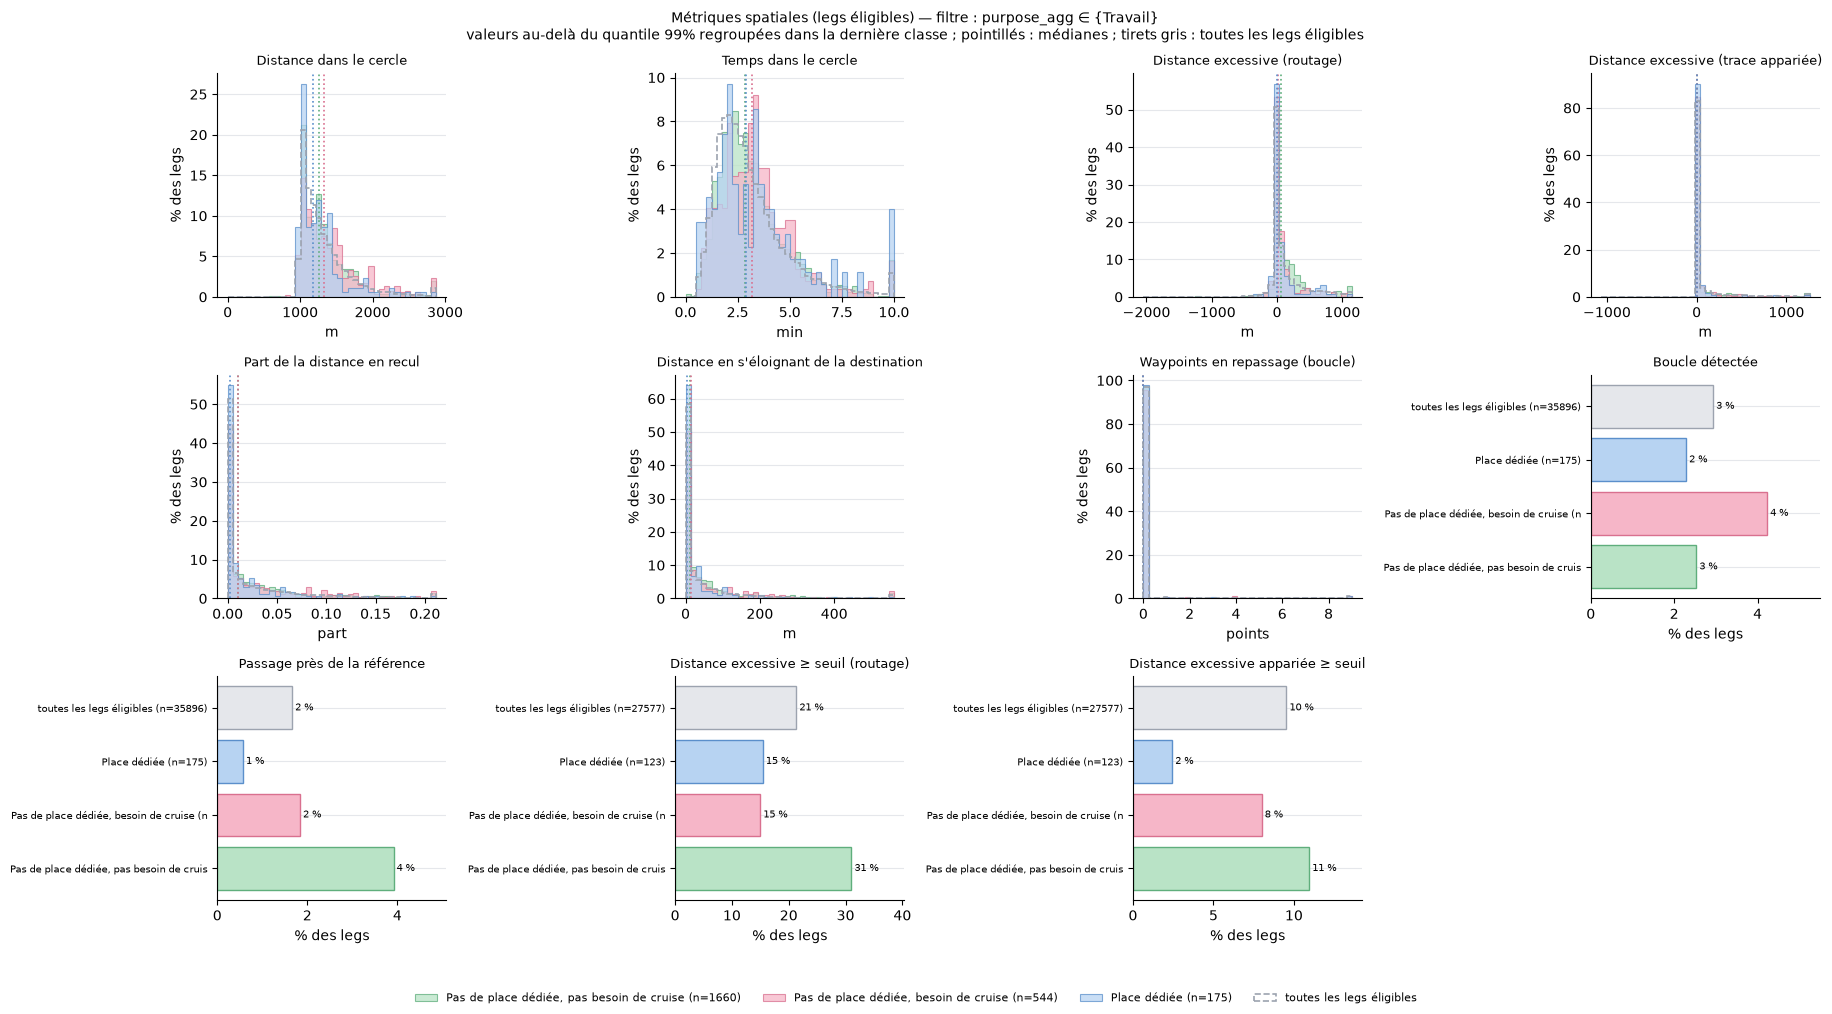

In [17]:
PANEL_PARKING = {}                   # ex. {"space_home": ["Pas de place dédiée, besoin de cruise"]}
PANEL_PARKING_MODE = "and"           # "and" ou "or"
PANEL_PURPOSES = ["Travail"]                # ex. ["Travail", "Retour à la maison"]
PANEL_GROUP_BY = "space_work"        # None, "space_home", "space_work" ou "purpose_agg"

eligible = legs[legs["spatial_eligible"]]
selection, label = filter_legs(eligible, parking=PANEL_PARKING, parking_mode=PANEL_PARKING_MODE,
                               purposes=PANEL_PURPOSES, purpose_column="purpose_agg")
fig = plot_metrics_panel(eligible, selection=selection, selection_label=label, group_by=PANEL_GROUP_BY)
fig.savefig(Path(config["_project_root"]) / OUTPUT_DIR / "figures" / "22_spatial_metrics_panel.png", dpi=150)
display(fig)
plt.close(fig)

## Map matching des fenêtres (OSRM `/match`)

Les waypoints de la fenêtre (avec le point d'entrée interpolé en tête, comme pour le routage) sont appariés au réseau par le conteneur OSRM. On obtient la **longueur de la fenêtre sur le réseau**, qui ne coupe plus les virages entre deux waypoints, et la métrique **`spatial_dist_excess_matched_m` = longueur appariée − plus court chemin routé**.

Le paquet `mappymatch` (classe `OsrmMatcher`) appelle ce même service, mais dans sa version 0.5 il ne renvoie ni la géométrie ni la longueur appariée (`geom=None`, marqué TODO dans son code), ne garde que le premier tronçon et n'envoie ni horodatages ni précision GPS : on appelle donc `/match` directement, avec ces options.

**Prérequis** : le conteneur OSRM démarré ; `OSRM_MATCH_URL` est son port à lui (colonne PORTS de `docker compose ps`), pas celui de l'API xyt (8010). Les résultats sont ajoutés par leg à `data/map_matching_by_leg.parquet` ; relancer le notebook depuis le haut pour les intégrer à `spatial_by_leg`.

osrm_url                   http://127.0.0.1:5530
nearest                                       Ok
test_match                                    Ok
test_matched_distance_m                    612.1
Name: OSRM /match, dtype: object

[matching] 200/300 legs — 1 s
[matching] 300/300 legs — 2 s


matching_status
matched     298
no_match      2
Name: appariement, dtype: int64

,points_sent,points_matched,n_matchings,confidence,spatial_window_distance_m,matched_distance_m,matched_minus_raw_m,matched_minus_raw_share
count,300.00,300.00,300.00,298.00,300.00,298.00,298.00,298.00
mean,62.77,21.26,1.25,0.88,1313.96,1184.73,-130.25,-0.10
std,31.62,9.44,0.55,0.24,372.15,479.68,329.80,0.25
min,8.00,0.00,0.00,0.00,858.24,53.20,-1197.44,-0.95
25%,33.00,14.00,1.00,0.95,1068.08,1002.12,-210.07,-0.15
50%,62.50,20.00,1.00,0.98,1208.97,1131.05,-6.17,-0.01
75%,100.00,27.25,1.00,0.98,1415.78,1366.52,9.76,0.01
max,100.00,53.00,4.00,0.99,3549.01,3701.40,1763.58,0.93


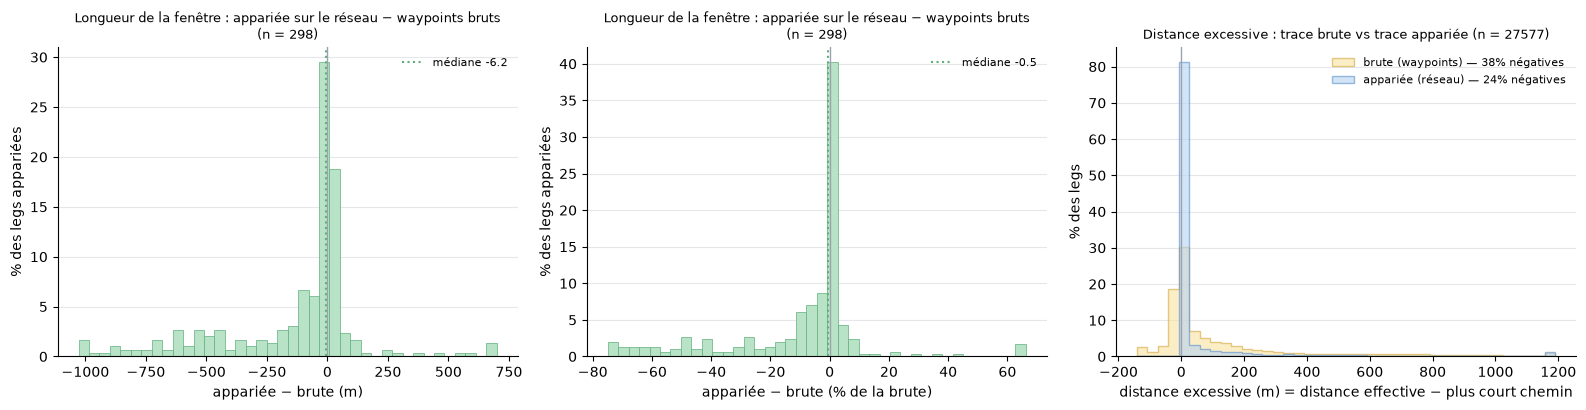

In [11]:
from parking_search_prediction.map_matching import (
    check_osrm, load_matching, plot_matching_distributions, run_map_matching, write_matching_map,
)
from parking_search_prediction.spatial_waypoints import apply_detection, load_routing

OSRM_MATCH_URL = "http://127.0.0.1:5530"   # port du conteneur OSRM (docker compose ps)
MATCH_SCOPE = "sample"                    # "sample" ou "all" (toutes les legs éligibles)
MATCH_SAMPLE_LEGS = 300
MATCH_MAX_POINTS = 100                    # limite d'OSRM par requête
MATCH_MAP_LEGS = 15

config.setdefault("map_matching", {}).update({"osrm_url": OSRM_MATCH_URL, "max_points": MATCH_MAX_POINTS})
display(pd.Series(check_osrm(config), name="OSRM /match"))

candidates = legs.loc[legs["spatial_eligible"] & legs["spatial_entry_lon"].notna(), "leg_id"]
match_ids = candidates.tolist() if MATCH_SCOPE == "all" else candidates.sample(min(MATCH_SAMPLE_LEGS, len(candidates)), random_state=42).tolist()
matching = run_map_matching(config, legs, match_ids)
legs = apply_detection(legs, spatial_settings(config), load_routing(config), load_matching(config))

display(matching["matching_status"].value_counts().rename("appariement"))
display(matching[["points_sent", "points_matched", "n_matchings", "confidence", "spatial_window_distance_m",
                  "matched_distance_m", "matched_minus_raw_m", "matched_minus_raw_share"]].describe().round(2))
fig = plot_matching_distributions(matching, legs)
display(fig)
plt.close(fig)

In [7]:
# Carte : waypoints bruts (points orange), recalage de chaque point (traits gris), trace appariée (vert), plus court chemin (bleu)
matched_ok = matching[matching["matching_status"].eq("matched")]
by_gap = matched_ok.reindex(matched_ok["matched_minus_raw_m"].abs().sort_values(ascending=False).index)
map_ids = list(dict.fromkeys(by_gap["leg_id"].head(MATCH_MAP_LEGS // 2).tolist()
                             + matched_ok["leg_id"].sample(min(MATCH_MAP_LEGS, len(matched_ok)), random_state=1).tolist()))[:MATCH_MAP_LEGS]
map_path = write_matching_map(config, map_ids)
from IPython.display import HTML
display(HTML(f"<a href='{Path(map_path).as_uri()}' target='_blank'>Ouvrir la carte du map matching</a>") if map_path else "Rien à afficher.")

### Diagnostic des détours de la trace appariée

Rejoue l'appariement des legs de la carte avec plusieurs réglages, et mesure pour chaque pas apparié le rapport *distance sur le réseau / vol d'oiseau* entre deux points recalés consécutifs. Un rapport > 3 sur un pas de quelques dizaines de mètres est un **détour forcé** : sens unique ou interdiction de tourner, rue roulée mais absente du graphe (zone piétonne, voie de bus, accès riverains, parking), ou recalage sur la mauvaise chaussée d'une route à deux voies séparées. Comparer les variantes indique si c'est un problème de réglage (rayon trop petit, horodatages) ou de graphe.

In [8]:
from parking_search_prediction.map_matching import VARIANTS, diagnose_matching

OSRM_FASTEST_URL = "http://127.0.0.1:5530"     # ex. "http://127.0.0.1:5000" : conteneur « car » (le plus rapide), pour comparer au profil distance
variants = dict(VARIANTS)
if OSRM_FASTEST_URL:
    variants["profil car (rapide)"] = {"osrm_url": OSRM_FASTEST_URL}

diagnostic = diagnose_matching(config, legs, map_ids, variants)
display(diagnostic.groupby("variante", sort=False)[["appariee_moins_brute_m", "confiance", "troncons", "part_points_apparies",
                                                   "detour_max", "pas_detour_sup_3"]].median().round(2))
diagnostic.sort_values(["leg_id", "variante"]).round(2)

,appariee_moins_brute_m,confiance,troncons,part_points_apparies,detour_max,pas_detour_sup_3
variante,,,,,,
actuel,-697.83,0.97,1.0,0.23,1.19,0.0
rayon 15–50 m,-674.73,0.91,2.0,0.32,1.19,0.0
rayon 25–80 m,-658.13,0.49,2.0,0.33,1.15,0.0
sans horodatages,-51.43,0.98,1.0,0.57,1.19,0.0
sans tidy,-703.93,0.79,3.0,0.76,1.24,0.0
profil car (rapide),-116.92,0.98,1.0,0.29,1.22,0.0


,leg_id,variante,code,longueur_brute_m,longueur_appariee_m,appariee_moins_brute_m,confiance,troncons,part_points_apparies,detour_max,pas_detour_sup_3
36,310a1501-8a8e-4897-bf85-c216b94e3fa3,actuel,Ok,1343.32,1296.8,-46.52,0.98,1,0.77,1.04,0
41,310a1501-8a8e-4897-bf85-c216b94e3fa3,profil car (rapide),Ok,1343.32,1296.9,-46.42,0.98,1,0.85,1.04,0
37,310a1501-8a8e-4897-bf85-c216b94e3fa3,rayon 15–50 m,Ok,1343.32,1324.2,-19.12,0.96,1,0.85,1.04,0
38,310a1501-8a8e-4897-bf85-c216b94e3fa3,rayon 25–80 m,Ok,1343.32,1324.2,-19.12,0.96,1,0.85,1.04,0
39,310a1501-8a8e-4897-bf85-c216b94e3fa3,sans horodatages,Ok,1343.32,1296.9,-46.42,0.98,1,0.88,1.04,0
...,...,...,...,...,...,...,...,...,...,...,...
53,df78e80a-d3c6-4c8d-a733-50d108ed3733,profil car (rapide),Ok,1334.09,1337.0,2.91,0.98,1,0.25,1.15,0
49,df78e80a-d3c6-4c8d-a733-50d108ed3733,rayon 15–50 m,Ok,1334.09,1337.1,3.01,0.98,1,0.23,1.15,0
50,df78e80a-d3c6-4c8d-a733-50d108ed3733,rayon 25–80 m,Ok,1334.09,1337.1,3.01,0.98,1,0.23,1.15,0
51,df78e80a-d3c6-4c8d-a733-50d108ed3733,sans horodatages,Ok,1334.09,1337.2,3.11,0.98,1,0.48,1.13,0


## Demande de routage

Écrit `data/routing_requests.parquet`, avec jusqu'à deux demandes par leg :

| Type (`ROUTING_REQUEST_TYPES`) | `route_type` | Origine → destination | Distance observée |
|---|---|---|---|
| `raw_od` | `buffer_entry_to_leg_end` | point d'entrée interpolé → dernier waypoint brut | distance entre waypoints dans le cercle |
| `matched_od` | `matched_entry_to_matched_end` | 1re → dernière position **recalée** par le map matching | longueur appariée |

L'OD corrigée fait partir et arriver le plus court chemin aux mêmes points que la trace appariée : les deux distances couvrent exactement les mêmes extrémités sur le réseau. Elle exige que la cellule de map matching ait tourné (seulement les appariements d'un seul tenant, `matched_od_single_matching_only`). Le notebook 27 route les deux et les affiche sur la carte ; relancer ensuite ce notebook depuis le haut, avec `ROUTING_REFERENCE` = `"raw_od"` ou `"matched_od"`.

In [9]:
ROUTING_REQUESTS_SCOPE = "eligible"          # "eligible" ou "all_with_window"
ROUTING_REQUEST_TYPES = ["raw_od", "matched_od"]

settings = spatial_settings(config)
settings["routing_requests_scope"] = ROUTING_REQUESTS_SCOPE
settings["routing_request_types"] = ROUTING_REQUEST_TYPES
routing_summary = write_routing_requests(config, legs, settings)
display(pd.Series({k: v for k, v in routing_summary.items() if k != "by_route_type"}, name="demandes de routage"))
display(pd.Series(routing_summary["by_route_type"], name="demandes par type de route"))
pd.read_parquet(routing_summary["path"]).head()

path               /Users/maximiliantrique/Documents/Projet_pytho...
scope                                                       eligible
requests                                                       63458
buffer_radius_m                                               1000.0
Name: demandes de routage, dtype: object

buffer_entry_to_leg_end         35896
matched_entry_to_matched_end    27562
Name: demandes par type de route, dtype: int64

,leg_id,route_type,origin_lon,origin_lat,destination_lon,destination_lat,observed_distance_m,observed_duration_s,routing_request_id,buffer_radius_m,created_at
0,00181b52-062f-4fa4-a0c3-f23241cca9c4,buffer_entry_to_leg_end,6.213930,46.392351,6.223176,46.386027,1507.937908,154.416806,6817849d26e4278d,1000.0,2026-11-11T10:54:45+00:00
1,001a0cf0-bb47-4133-94aa-816f837d85a9,buffer_entry_to_leg_end,6.374263,46.071838,6.387174,46.071431,1249.309219,172.842572,6ef444b2b457e4b6,1000.0,2026-11-11T10:54:45+00:00
2,001f4cd8-f023-4138-aba9-51df64d580d5,buffer_entry_to_leg_end,6.362297,46.270967,6.371160,46.264399,1105.413989,151.459095,c083500ee4d3861c,1000.0,2026-11-11T10:54:45+00:00
3,0021e19d-89d2-43c1-8e6d-f92bc78b1000,buffer_entry_to_leg_end,6.120750,46.181697,6.112430,46.188591,1814.470076,216.928767,066f89e2ef75bfc7,1000.0,2026-11-11T10:54:45+00:00
4,0034e051-e3c3-4e3c-9709-e63e676a9044,buffer_entry_to_leg_end,6.313826,46.269574,6.323429,46.275621,1285.915148,136.969220,2d77b349628a7bf2,1000.0,2026-11-11T10:54:45+00:00
